# Gasto en intereses de la deuda pública

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "intereses-deuda-publica"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto en intereses de la deuda pública"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # intereses a pagar (brutos) de las administraciones públicas sobre el PIB a precios corrientes
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Los intereses que paga en un año el conjunto de las administraciones públicas por su deuda (letras, bonos, obligaciones y préstamos), en porcentaje del PIB. En España incluye el Estado, las comunidades autónomas, las entidades locales y la Seguridad Social; en los demás países, sus equivalentes. En contabilidad nacional es la partida D.41 (intereses) a pagar.

**Cómo se lee.** Un valor de 2,5 significa que ese año los intereses equivalieron al 2,5 % del PIB. La cifra depende de cuánta deuda hay (gráfica de deuda pública) y del tipo de interés medio que se paga por ella, que sigue a los tipos de mercado con retraso, a medida que vence la deuda emitida en años anteriores y se sustituye por deuda nueva. Los intereses forman parte del gasto público total; el saldo de las cuentas públicas sin contar los intereses se llama *saldo primario*.

**Limitaciones.**
- Son intereses brutos: no se restan los que cobran las administraciones por sus activos financieros (depósitos, préstamos concedidos, títulos), que en algunos países son importantes.
- Se registran por devengo, con los criterios de la contabilidad nacional, y pueden no coincidir con los intereses que figuran en los presupuestos de cada año.
- La OCDE no publica su media de este indicador: se calcula en este notebook con los datos de los países miembros que da la propia OCDE, ponderados por el tamaño de cada economía, de modo que pesan más los países grandes (ver notas). La media de la UE-27 también pondera por el tamaño.
- Los datos de España anteriores a 1995 y los de Canadá anteriores a 1981 no siguen la metodología contable vigente: la OCDE los reconstruye hacia atrás con otras fuentes (ver notas).
- Solo se muestran años con dato observado: se descartan las proyecciones que acompañan a cada edición del *Economic Outlook* de la OCDE.

## 2. Descarga

- **España, EE. UU. y Canadá:** OCDE, *Economic Outlook* (`OECD.ECO.MAD,DSD_EO@DF_EO`), variables `GGINTP` (pagos brutos de intereses de las administraciones públicas, moneda nacional a precios corrientes) y `GDP` (PIB nominal, moneda nacional). El *Economic Outlook* no publica los intereses brutos en porcentaje del PIB (solo los netos, `GNINTQ`): la ratio se calcula en la sección 3.
- **Media de la OCDE:** `GGINTP`, `GDP` y paridades de poder adquisitivo (`PPP`) de los 38 países miembros, del mismo dataflow. El área `OECD` no tiene `GGINTP` en el *Economic Outlook*, así que la media se calcula en la sección 3.
- **Último año observado:** fichero *Last historical points* de la misma edición del *Economic Outlook*, enlazado en los metadatos del dataflow; sirve para descartar las proyecciones.
- **UE-27:** Eurostat `gov_10a_main` (sector `S13`, `D41PAY`, `PC_GDP`), intereses a pagar de las administraciones públicas en % del PIB.

Solo para las comprobaciones y las notas de la sección 3 (no se publican como series): los intereses netos (`GNINTQ`) de los países miembros y del área `OECD` del *Economic Outlook*, para validar el cálculo de la media; España en Eurostat (`gov_10a_main`, `D41PAY`, en % del PIB y en millones de euros, y el PIB en millones de euros de `gov_10dd_edpt1`), y los intereses a pagar (`D41`) de las administraciones públicas de EE. UU. y Canadá en las cuentas nacionales anuales de la OCDE (`OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
import re
import xml.etree.ElementTree as ET

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# OCDE, Economic Outlook. Cada edición publica una versión nueva del dataflow y la versión fija la edición
# (datos y fichero de últimos datos observados); la sección 3 comprueba que sea la última publicada.
DATAFLOW = "OECD.ECO.MAD,DSD_EO@DF_EO,1.5"
# Clave: REF_AREA.MEASURE.FREQ · A: anual
# GGINTP: pagos brutos de intereses de las AA. PP. y GDP: PIB nominal, los dos en moneda nacional a precios corrientes
# (sin multiplicador, UNIT_MULT = 0) · PPP: paridad de poder adquisitivo (moneda nacional por dólar)
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada"}
# Los 38 países miembros de la OCDE, con su nombre para las notas
MIEMBROS_OCDE = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile",
    "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca",
    "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia", "GBR": "Reino Unido",
    "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania", "LUX": "Luxemburgo", "LVA": "Letonia",
    "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega", "NZL": "Nueva Zelanda", "POL": "Polonia",
    "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "TUR": "Turquía",
    "USA": "Estados Unidos",
}


def pedir_oecd(url, etiqueta):
    """GET de metadatos o ficheros de la OCDE, con los reintentos de lib/_http."""
    return pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta=etiqueta,
        mensaje=lambda r: r.text[:200],
    )


def metadatos_eo():
    """Última versión publicada del dataflow y URL del fichero «Last historical points» de la versión usada."""
    agencia, flujo, version = DATAFLOW.split(",")
    base = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}"
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    ultima = ET.fromstring(pedir_oecd(f"{base}/latest", "versión").content).find(".//s:Dataflow", ns).get("version")
    texto = pedir_oecd(f"{base}/{version}", "metadatos").text
    urls = sorted(set(re.findall(r"https://[^\s\"'<>&]+Last_Historical[^\s\"'<>&]+\.xlsx", texto)))
    if len(urls) != 1:
        raise oecd.OecdError(f"se esperaba un enlace al fichero de últimos datos observados y hay {len(urls)}")
    return ultima, urls[0]


def ultimos_observados(url, variables):
    """Último año observado (no proyectado) de cada variable por país, según el fichero «Last historical points»."""
    bruto = pd.read_excel(io.BytesIO(pedir_oecd(url, "últimos datos observados").content), header=None)
    fila = next(i for i, v in bruto.iloc[:, 0].items() if v == "Country Code")
    tabla = bruto.iloc[fila + 1:].set_axis(bruto.iloc[fila].tolist(), axis=1)
    resultado = {}
    for variable in variables:
        t = tabla[tabla["Variable code"] == variable]
        resultado[variable] = {
            c: int(a) for c, a in zip(t["Country Code"], t["Last Observation annual"]) if pd.notna(a)
        }
    return resultado


# Intereses, PIB y PPA de los países miembros (incluidos España, EE. UU. y Canadá)
miembros = {c: c for c in MIEMBROS_OCDE}
m_int, fuentes_eo = oecd.get(DATAFLOW, "{AREA}.GGINTP.A", areas=miembros, desde=DESDE)
m_pib, _ = oecd.get(DATAFLOW, "{AREA}.GDP.A", areas=miembros, desde=DESDE)
m_ppa, _ = oecd.get(DATAFLOW, "{AREA}.PPP.A", areas=miembros, desde=DESDE)
version_ultima, url_lho = metadatos_eo()
ultimo_lho = ultimos_observados(url_lho, ["GGINTP", "GDP"])
EDICION = re.search(r"EO_?(\d+)\.xlsx$", url_lho).group(1)

# Solo para validar el cálculo de la media: intereses netos en % del PIB de los miembros y media publicada (OECD)
m_netos, _ = oecd.get(DATAFLOW, "{AREA}.GNINTQ.A", areas={**miembros, "OECD": "OECD"}, desde=DESDE)

# Eurostat: intereses a pagar de las AA. PP., UE-27 (serie publicada) y España (para comparar con la OCDE)
D41 = {"freq": "A", "sector": "S13", "na_item": "D41PAY"}
d41, fuentes_d41 = eurostat.get(
    "gov_10a_main", {**D41, "unit": "PC_GDP"}, geos={"EU27_2020": "ue27", "ES": "espana_eurostat"}, desde=DESDE,
)
d41_meur, _ = eurostat.get("gov_10a_main", {**D41, "unit": "MIO_EUR"}, geos={"ES": "espana_eurostat"}, desde=DESDE)
pib_meur, _ = eurostat.get(
    "gov_10dd_edpt1", {"freq": "A", "unit": "MIO_EUR", "sector": "S1", "na_item": "B1GQ"},
    geos={"ES": "espana_eurostat"}, desde=DESDE,
)

# OCDE, cuentas nacionales anuales (tabla 0200): intereses a pagar (D41) de las AA. PP. de EE. UU. y Canadá, para
# comparar con el Economic Outlook. Clave: FREQ.REF_AREA.SECTOR.COUNTERPART_SECTOR.ACCOUNTING_ENTRY.TRANSACTION.
# INSTR_ASSET.EXPENDITURE.UNIT_MEASURE.VALUATION.PRICE_BASE.TRANSFORMATION.TABLE_IDENTIFIER
CUENTAS = "OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12,1.1"
ESCALA_CUENTAS = 1e6  # esta tabla publica millones de moneda nacional (UNIT_MULT = 6)
d41_cn, _ = oecd.get(CUENTAS, "A.{AREA}.S13._Z.D.D41._Z._Z.XDC.S.V.N.T0200", areas={"USA": "USA", "CAN": "CAN"}, desde=DESDE)
print(f"Economic Outlook {EDICION} (dataflow versión {DATAFLOW.rsplit(',', 1)[1]})")

Economic Outlook 119 (dataflow versión 1.5)


## 3. Transformación

- **España, EE. UU. y Canadá:** intereses brutos (`GGINTP`) entre PIB nominal (`GDP`), por 100. Las dos variables están en moneda nacional a precios corrientes, así que no hace falta deflactor ni tipo de cambio.
- **Media de la OCDE:** media de la misma ratio en los países miembros con dato, ponderada por el PIB en dólares PPA (PIB nominal entre PPA), que es como agrega la OCDE las ratios en el *Economic Outlook*. Como los países con dato cambian con los años (la serie de muchos empieza en 1995), la media se **encadena**: su nivel es el del primer año con el máximo de países y, hacia atrás y hacia delante, cada año suma la variación de la media calculada solo con los países que tienen dato ese año y el contiguo. Así la entrada o salida de un país no crea un salto. Las comprobaciones aplican el mismo cálculo a los intereses netos (`GNINTQ`), para los que la OCDE sí publica su media, y lo comparan con ella.
- **Proyecciones:** cada país llega hasta su último año observado, el menor de los de `GGINTP` y `GDP` en el fichero *Last historical points* de la misma edición. Ese fichero no da fecha para los agregados: la media de la OCDE se corta en el último año en que **todos** los países que la componen tienen dato observado.
- **UE-27:** la serie de Eurostat tal cual.

In [ ]:
P = lambda d: d.pivot(index="periodo", columns="serie", values="valor")
INT, PIB, PPA = P(m_int), P(m_pib), P(m_ppa)
ratio = INT / PIB[INT.columns] * 100  # intereses brutos en % del PIB, por país
peso = PIB / PPA  # PIB en dólares PPA: peso de cada país en la media


def media_encadenada(valores, peso):
    """Media de los países ponderada por `peso`, encadenada para que la entrada o salida de países no cree saltos.

    Devuelve (media por año, países con dato por año, año base). El nivel es la media ponderada del primer año con
    el máximo de países; cada año siguiente (o anterior) suma la variación de la media calculada solo con los
    países que tienen dato en los dos años.
    """
    peso = peso.reindex(index=valores.index, columns=valores.columns)
    ok = valores.notna() & peso.notna()
    anios = [int(a) for a in valores.index[ok.any(axis=1)]]
    if anios != list(range(anios[0], anios[-1] + 1)):
        raise ValueError("años no consecutivos")

    def media(anio, paises):
        return (valores.loc[anio, paises] * peso.loc[anio, paises]).sum() / peso.loc[anio, paises].sum()

    paises = {a: list(ok.columns[ok.loc[a]]) for a in anios}
    base = max(anios, key=lambda a: (len(paises[a]), -a))  # primer año con el máximo de países
    nivel = {base: media(base, paises[base])}
    for a in range(base + 1, anios[-1] + 1):  # hacia delante
        comunes = [c for c in paises[a] if c in paises[a - 1]]
        nivel[a] = nivel[a - 1] + media(a, comunes) - media(a - 1, comunes)
    for a in range(base - 1, anios[0] - 1, -1):  # hacia atrás
        comunes = [c for c in paises[a] if c in paises[a + 1]]
        nivel[a] = nivel[a + 1] - (media(a + 1, comunes) - media(a, comunes))
    return pd.Series(nivel).sort_index(), pd.Series({a: set(p) for a, p in paises.items()}), base


# Países de la media: los miembros con GGINTP en el Economic Outlook
miembros_media = sorted(ratio.columns[ratio.notna().any()])
sin_fecha = [c for c in miembros_media if not all(c in ultimo_lho[v] for v in ("GGINTP", "GDP"))]
if sin_fecha:
    raise ValueError(f"sin último año observado en el fichero de la OCDE: {', '.join(sin_fecha)}")
ultimo_obs = {c: min(ultimo_lho["GGINTP"][c], ultimo_lho["GDP"][c]) for c in miembros_media}

media, paises, BASE = media_encadenada(ratio[miembros_media], peso[miembros_media])

ULTIMO = {AREAS[c]: ultimo_obs[c] for c in AREAS}
ULTIMO["ocde"] = min(ultimo_obs[c] for c in miembros_media)
print("Último año observado:", ULTIMO)

largo = lambda s, nombre: s.dropna().rename_axis("periodo").reset_index(name="valor").assign(serie=nombre)
eo_todo = pd.concat([largo(ratio[c], s) for c, s in AREAS.items()] + [largo(media, "ocde")], ignore_index=True)
eo_todo = eo_todo[["serie", "periodo", "valor"]]
proyectado = eo_todo["periodo"] > eo_todo["serie"].map(ULTIMO)
print("Años descartados (proyecciones):", {
    s: f"{g.min()}-{g.max()}" for s, g in eo_todo[proyectado].groupby("serie")["periodo"]
})
eo = eo_todo[~proyectado]

ue27 = d41[d41["serie"] == "ue27"]
df = pd.concat([eo, ue27], ignore_index=True)

CODIGO_EO = f"{DATAFLOW} (Economic Outlook {EDICION}; GGINTP / GDP × 100, sin proyecciones)"
CODIGO_MEDIA = (
    f"{DATAFLOW} (Economic Outlook {EDICION}; GGINTP / GDP × 100 de {len(miembros_media)} países "
    f"miembros, media encadenada ponderada por el PIB en PPA, cálculo propio; sin proyecciones)"
)
f0 = fuentes_eo[0]
fuentes = [FuenteMeta(s, f0.organismo, CODIGO_EO, f0.url, f0.fecha_consulta) for s in AREAS.values()]
fuentes.append(FuenteMeta("ocde", f0.organismo, CODIGO_MEDIA, f0.url, f0.fecha_consulta))
fuentes += [
    FuenteMeta(f.serie, f.organismo, "gov_10a_main (S13, D41PAY, PC_GDP)", f.url, f.fecha_consulta)
    for f in fuentes_d41 if f.serie == "ue27"
]
assert df["valor"].between(0, 15).all(), "intereses fuera de rango: ¿unidades?"
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(12)

Último año observado: {'espana': 2025, 'eeuu': 2025, 'canada': 2025, 'ocde': 2023}
Años descartados (proyecciones): {'canada': '2026-2027', 'eeuu': '2026-2027', 'espana': '2026-2027', 'ocde': '2024-2027'}


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2014,3.10,3.98,3.53,2.91,2.5
2015,3.07,3.82,3.07,2.72,2.2
2016,2.97,3.92,2.78,2.68,2.0
2017,2.84,3.91,2.53,2.61,1.8
2018,2.94,4.00,2.44,2.58,1.7
2019,2.96,4.10,2.25,2.52,1.5
2020,2.93,3.80,2.23,2.35,1.4
2021,2.63,3.59,2.12,2.28,1.4
2022,2.67,3.71,2.31,2.52,1.6


### Comprobaciones

No cambian los datos publicados:
1. Que la versión fijada del dataflow sea la última que publica la OCDE.
2. España: la ratio de la OCDE frente a la de Eurostat (`gov_10a_main`, `D41PAY`), la publicada (un decimal) y la recalculada con los importes en millones de euros (intereses entre PIB). Si no coincidieran, las series de la OCDE no serían comparables con la de la UE-27.
3. Media de la OCDE: el mismo cálculo (media encadenada ponderada por el PIB en PPA) aplicado a los intereses netos (`GNINTQ`) de los países miembros, frente a la media que publica la OCDE, y la media sin encadenar como contraste. También, los países que componen la media de los intereses brutos cada año y el peso de los que tienen proyecciones en los años posteriores al corte.
4. EE. UU. y Canadá: los intereses del *Economic Outlook* frente a los intereses a pagar (`D41`) de las administraciones públicas en las cuentas nacionales anuales de la OCDE.

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]

# 1) Versión del dataflow
version = DATAFLOW.rsplit(",", 1)[1]
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza DATAFLOW.")
else:
    print(f"La versión usada del dataflow ({version}) es la última publicada por la OCDE.")

# 2) España: OCDE frente a Eurostat
comp = pd.DataFrame({
    "OCDE": serie(eo, "espana"),
    "Eurostat publicado": serie(d41, "espana_eurostat"),
    "Eurostat recalculado": serie(d41_meur, "espana_eurostat") / serie(pib_meur, "espana_eurostat") * 100,
}).dropna()
comp["dif. publicado"] = comp["OCDE"] - comp["Eurostat publicado"]
comp["dif. recalculado"] = comp["OCDE"] - comp["Eurostat recalculado"]
COMUN = (int(comp.index.min()), int(comp.index.max()))
DIF_PUB = comp["dif. publicado"].abs().max()
DIF_CALC = comp["dif. recalculado"].abs().max()
print(f"\nEspaña {COMUN[0]}-{COMUN[1]}: diferencia máxima OCDE − Eurostat {DIF_PUB:.3f} (publicado), {DIF_CALC:.4f} (recalculado)")
display(comp.iloc[::3].round(3))

# 3) Media de la OCDE: validación con los intereses netos (GNINTQ) y composición de la media de los brutos
netos = P(m_netos)
miembros_netos = [c for c in netos.columns if c in MIEMBROS_OCDE]
media_netos, paises_netos, BASE_NETOS = media_encadenada(netos[miembros_netos], peso[miembros_netos])
p = peso[miembros_netos].where(netos[miembros_netos].notna())
sin_encadenar = (netos[miembros_netos] * p).sum(axis=1) / p.sum(axis=1)
val = pd.DataFrame({
    "países": paises_netos.map(len), "publicada": netos["OECD"], "encadenada": media_netos,
    "sin encadenar": sin_encadenar,
}).loc[DESDE: ULTIMO["ocde"]].dropna(subset=["publicada"])
val["dif. encadenada"] = val["encadenada"] - val["publicada"]
val["dif. sin encadenar"] = val["sin encadenar"] - val["publicada"]
VAL = (int(val.index.min()), int(val.index.max()))
DIF_MEDIA = val["dif. encadenada"].abs().max()
DIF_SIN = val["dif. sin encadenar"].abs().max()
print(f"\nIntereses netos {VAL[0]}-{VAL[1]}: diferencia máxima con la media publicada por la OCDE "
      f"{DIF_MEDIA:.3f} (encadenada, base {BASE_NETOS}) y {DIF_SIN:.3f} (sin encadenar)")
display(val.round(3).iloc[::4])

N_MEDIA = len(miembros_media)
SIN_SERIE = sorted(MIEMBROS_OCDE[c] for c in MIEMBROS_OCDE if c not in miembros_media)
comp_media = paises.loc[DESDE: ULTIMO["ocde"]]
A0, N0 = int(comp_media.index[0]), len(comp_media.iloc[0])
print(f"\nMedia de los intereses brutos: {N_MEDIA} miembros con GGINTP (sin {', '.join(SIN_SERIE)}); año base {BASE}.")
SALEN = {}
for a in comp_media.index[1:]:
    entran, salen = comp_media[a] - comp_media[a - 1], comp_media[a - 1] - comp_media[a]
    if entran or salen:
        print(f"  {a}: {len(comp_media[a])} países" + (f"; entran {', '.join(sorted(entran))}" if entran else "")
              + (f"; salen {', '.join(sorted(salen))}" if salen else ""))
    if salen:
        SALEN[int(a)] = sorted(MIEMBROS_OCDE[c] for c in salen)
A_COMPLETA = int(min(a for a in comp_media.index if len(comp_media[a]) == comp_media.map(len).max()))

fin = max(ULTIMO.values())
PROYECTADOS = sorted({
    MIEMBROS_OCDE[c] for a in range(ULTIMO["ocde"] + 1, fin + 1) for c in paises[a] if ultimo_obs[c] < a
})
for a in range(ULTIMO["ocde"] + 1, fin + 1):
    proy = sorted(c for c in paises[a] if ultimo_obs[c] < a)
    g = peso.loc[a, sorted(paises[a])]
    print(f"{a}: con proyección {', '.join(MIEMBROS_OCDE[c] for c in proy)}: "
          f"{fmt(g[proy].sum() / g.sum() * 100)} % del PIB en PPA de la media")

# 4) EE. UU. y Canadá: Economic Outlook frente a las cuentas nacionales anuales de la OCDE
cn = P(d41_cn) * ESCALA_CUENTAS
CN = {}
for c in ("USA", "CAN"):
    t = pd.DataFrame({"EO": INT[c], "cuentas": cn[c], "PIB": PIB[c]}).loc[: ultimo_obs[c]].dropna()
    t["dif. %"] = (t["EO"] / t["cuentas"] - 1) * 100
    t["dif. puntos"] = (t["EO"] - t["cuentas"]) / t["PIB"] * 100
    assert t["dif. %"].abs().max() < 10, "diferencia excesiva: ¿multiplicador de unidades?"
    CN[c] = t
    print(f"\n{c} {t.index.min()}-{t.index.max()}: EO − cuentas nacionales entre {t['dif. %'].min():.2f} y "
          f"{t['dif. %'].max():.2f} % ({t['dif. puntos'].min():.3f} a {t['dif. puntos'].max():.3f} puntos del PIB)")
    display(t[["dif. %", "dif. puntos"]].iloc[::5].round(3))

La versión usada del dataflow (1.5) es la última publicada por la OCDE.

España 1995-2025: diferencia máxima OCDE − Eurostat 0.048 (publicado), 0.0000 (recalculado)


,OCDE,Eurostat publicado,Eurostat recalculado,dif. publicado,dif. recalculado
periodo,,,,,
1995,4.941,4.9,4.941,0.041,-0.0
1998,4.066,4.1,4.066,-0.034,-0.0
2001,2.970,3.0,2.970,-0.030,0.0
2004,1.989,2.0,1.989,-0.011,0.0
2007,1.579,1.6,1.579,-0.021,0.0
2010,1.897,1.9,1.897,-0.003,0.0
2013,3.564,3.6,3.564,-0.036,0.0
2016,2.781,2.8,2.781,-0.019,0.0
2019,2.252,2.3,2.252,-0.048,0.0



Intereses netos 1976-2023: diferencia máxima con la media publicada por la OCDE 0.049 (encadenada, base 1998) y 0.158 (sin encadenar)


,países,publicada,encadenada,sin encadenar,dif. encadenada,dif. sin encadenar
1976,15,1.890,1.904,2.048,0.014,0.158
1980,18,2.292,2.293,2.414,0.002,0.122
1984,18,3.390,3.411,3.532,0.021,0.141
1988,19,3.425,3.422,3.550,-0.003,0.125
1992,23,3.762,3.810,3.740,0.049,-0.022
1996,31,3.814,3.804,3.778,-0.009,-0.036
2000,32,2.737,2.737,2.737,-0.000,-0.000
2004,32,2.288,2.288,2.288,0.000,0.000
2008,32,2.102,2.102,2.102,-0.000,-0.000
2012,32,2.301,2.301,2.301,-0.000,-0.000



Media de los intereses brutos: 33 miembros con GGINTP (sin Chile, Colombia, Costa Rica, México, Turquía); año base 1998.
  1977: 16 países; entran PRT
  1978: 17 países; entran NOR
  1980: 18 países; entran ISL
  1986: 19 países; entran NZL
  1989: 20 países; entran AUS
  1990: 22 países; entran IRL, LUX
  1991: 23 países; entran DEU
  1995: 32 países; entran CZE, EST, GRC, HUN, LTU, LVA, POL, SVK, SVN
  1998: 33 países; entran ISR
  2022: 32 países; salen ISR
2024: con proyección Nueva Zelanda: 0,4 % del PIB en PPA de la media
2025: con proyección Suiza, Japón, Corea del Sur, Nueva Zelanda: 14,3 % del PIB en PPA de la media

USA 1976-2024: EO − cuentas nacionales entre -0.00 y 3.21 % (-0.000 a 0.201 puntos del PIB)


,dif. %,dif. puntos
periodo,,
1976,0.000,0.000
1981,2.069,0.114
1986,2.710,0.174
1991,2.719,0.176
1996,2.311,0.134
2001,2.637,0.112
2006,2.104,0.084
2011,2.015,0.088
2016,1.896,0.073



CAN 1981-2025: EO − cuentas nacionales entre 0.00 y 0.10 % (0.000 a 0.003 puntos del PIB)


,dif. %,dif. puntos
periodo,,
1981,0.0,0.0
1986,0.0,0.0
1991,0.0,0.0
1996,0.0,0.0
2001,0.0,0.0
2006,0.0,0.0
2011,0.0,0.0
2016,0.0,0.0
2021,0.0,0.0


### Notas

Una frase por decisión. Las cifras de las notas salen de las comprobaciones anteriores.

In [ ]:
def unir(nombres):
    nombres = list(nombres)
    return nombres[0] if len(nombres) == 1 else f"{', '.join(nombres[:-1])} y {nombres[-1]}"


# Rupturas: primer año con datos del sistema contable vigente en las cuentas no financieras de las AA. PP.
# (documentación de la base de datos del Economic Outlook, anexo A3.2, «Coverage and reporting systems»: «Time
# series are backcasted in the EO database using data from other sources»). Misma nota en gasto, déficit e intereses.
RUPTURAS = (
    "Rupturas de serie en 1995 en España y en 1981 en Canadá: el Economic Outlook da las cuentas de las "
    "administraciones públicas con la metodología vigente (SEC 2010 y SCN 2008) desde esos años, y los anteriores "
    "son retropolaciones de la OCDE con otras fuentes (documentación de la base de datos, anexo A3.2). En EE. UU., "
    "las cuentas NIPA vigentes cubren todo el periodo."
)

por_anio = {}
for s, nombre in [("espana", "España"), ("eeuu", "EE. UU."), ("canada", "Canadá")]:
    por_anio.setdefault(ULTIMO[s], []).append(nombre)
ultimos = "; ".join(f"{a} en {unir(n)}" for a, n in por_anio.items())

if DIF_CALC < 0.01:
    contraste = (
        f"coincide con la de Eurostat (gov_10a_main, D41PAY), la que se usa para la UE-27: las diferencias son "
        f"menores de 0,01 puntos al calcular la de Eurostat con los importes en millones de euros, y de hasta "
        f"{fmt(DIF_PUB, 2)} con la cifra que publica Eurostat, redondeada a un decimal."
    )
else:
    contraste = (
        f"difiere hasta en {fmt(DIF_CALC, 2)} puntos de la de Eurostat (gov_10a_main, D41PAY), la que se usa "
        f"para la UE-27."
    )

composicion = f"{N0} países en {A0} y los {N_MEDIA} desde {A_COMPLETA}" + "".join(
    f"; {len(paises[a])} desde {a}, porque la serie de {unir(n)} termina en {a - 1}" for a, n in SALEN.items()
)

def periodos(anios):
    """Años agrupados en tramos consecutivos: [1976, 1977, 1980] → «1976-1977 y 1980»."""
    anios, tramos = sorted(int(a) for a in anios), []
    for a in anios:
        if tramos and a == tramos[-1][1] + 1:
            tramos[-1][1] = a
        else:
            tramos.append([a, a])
    return unir(f"{a}-{b}" if a < b else f"{a}" for a, b in tramos)


eeuu, can = CN["USA"], CN["CAN"]
REF_CN = (
    "los intereses a pagar (D41) de las administraciones públicas en las cuentas nacionales anuales de la OCDE "
    "(DSD_NASEC10@DF_TABLE12)"
)
distinto = eeuu[eeuu["dif. %"].abs() >= 0.01]
iguales = eeuu.index.difference(distinto.index)
if distinto.empty:
    dif_eeuu = f"coinciden con {REF_CN} de {eeuu.index.min()} a {eeuu.index.max()}"
elif (distinto["dif. %"] > 0).all():
    dif_eeuu = (
        f"superan entre un {fmt(distinto['dif. %'].min())} y un {fmt(distinto['dif. %'].max())} % (entre "
        f"{fmt(distinto['dif. puntos'].min(), 2)} y {fmt(distinto['dif. puntos'].max(), 2)} puntos del PIB) a "
        f"{REF_CN} en {periodos(distinto.index)}"
        + (f", y coinciden con ellos en {periodos(iguales)}" if len(iguales) else "")
    )
else:
    dif_eeuu = (
        f"difieren hasta en {fmt(eeuu['dif. puntos'].abs().max(), 2)} puntos del PIB de {REF_CN} de "
        f"{eeuu.index.min()} a {eeuu.index.max()}"
    )
dif_can = can["dif. puntos"].abs().max()
texto_can = (
    "en Canadá las dos fuentes difieren en menos de 0,01 puntos" if dif_can < 0.01
    else f"en Canadá difieren hasta en {fmt(dif_can, 2)} puntos"
)

NOTAS = [
    f"España, EE. UU. y Canadá: OCDE, Economic Outlook n.º {EDICION} ({DATAFLOW.split(',')[1]}, versión "
    f"{DATAFLOW.rsplit(',', 1)[1]}), pagos brutos de intereses de las administraciones públicas (GGINTP) divididos "
    f"por el PIB nominal (GDP), los dos en moneda nacional a precios corrientes; el Economic Outlook no publica esta "
    f"ratio.",
    f"Se descartan las proyecciones del Economic Outlook: cada país llega hasta su último año observado de "
    f"intereses y PIB según el fichero «Last historical points» de la misma edición ({ultimos}).",
    f"Media OCDE: la OCDE no la publica para los intereses brutos; se calcula con la misma ratio de los países "
    f"miembros con dato en el Economic Outlook, ponderada por su PIB en dólares PPA (PIB nominal entre la paridad "
    f"de poder adquisitivo). Incluye {N_MEDIA} de los {len(MIEMBROS_OCDE)} miembros (no {unir(SIN_SERIE)}, sin "
    f"esta serie en el Economic Outlook) y su composición cambia con los datos disponibles: {composicion}.",
    f"Para que la entrada y salida de países no cree saltos, la media de la OCDE se encadena: su nivel es el de "
    f"{BASE}, primer año con todos los países, y la variación de cada año se calcula con los que tienen dato ese "
    f"año y el contiguo. Aplicado a los intereses netos (GNINTQ), cuya media sí publica la OCDE, este cálculo la "
    f"reproduce con diferencias de hasta {fmt(DIF_MEDIA, 2)} puntos de {VAL[0]} a {VAL[1]}, frente a "
    f"{fmt(DIF_SIN, 2)} de la media sin encadenar.",
    *(
        [f"La media de la OCDE llega hasta {ULTIMO['ocde']}, último año con dato observado en todos sus países; "
         f"en los años siguientes incluiría proyecciones de la OCDE para {unir(PROYECTADOS)}."]
        if ULTIMO["ocde"] < fin else []
    ),
    "Media UE-27: Eurostat gov_10a_main (sector S13, D41PAY, % del PIB), intereses a pagar de las "
    "administraciones públicas, que Eurostat publica con un decimal; agregado de composición actual (EU27_2020).",
    f"España: de {COMUN[0]} a {COMUN[1]}, la ratio de la OCDE {contraste}",
    f"EE. UU.: los intereses del Economic Outlook, que la OCDE elabora con las cuentas NIPA de EE. UU. (anexo A3.2 "
    f"de la documentación de su base de datos), {dif_eeuu}; {texto_can}.",
    RUPTURAS,
]
for n in NOTAS:
    print("-", n)

- España, EE. UU. y Canadá: OCDE, Economic Outlook n.º 119 (DSD_EO@DF_EO, versión 1.5), pagos brutos de intereses de las administraciones públicas (GGINTP) divididos por el PIB nominal (GDP), los dos en moneda nacional a precios corrientes; el Economic Outlook no publica esta ratio.
- Se descartan las proyecciones del Economic Outlook: cada país llega hasta su último año observado de intereses y PIB según el fichero «Last historical points» de la misma edición (2025 en España, EE. UU. y Canadá).
- Media OCDE: la OCDE no la publica para los intereses brutos; se calcula con la misma ratio de los países miembros con dato en el Economic Outlook, ponderada por su PIB en dólares PPA (PIB nominal entre la paridad de poder adquisitivo). Incluye 33 de los 38 miembros (no Chile, Colombia, Costa Rica, México y Turquía, sin esta serie en el Economic Outlook) y su composición cambia con los datos disponibles: 15 países en 1976 y los 33 desde 1998; 32 desde 2022, porque la serie de Israel termina en

## 4. Visualización

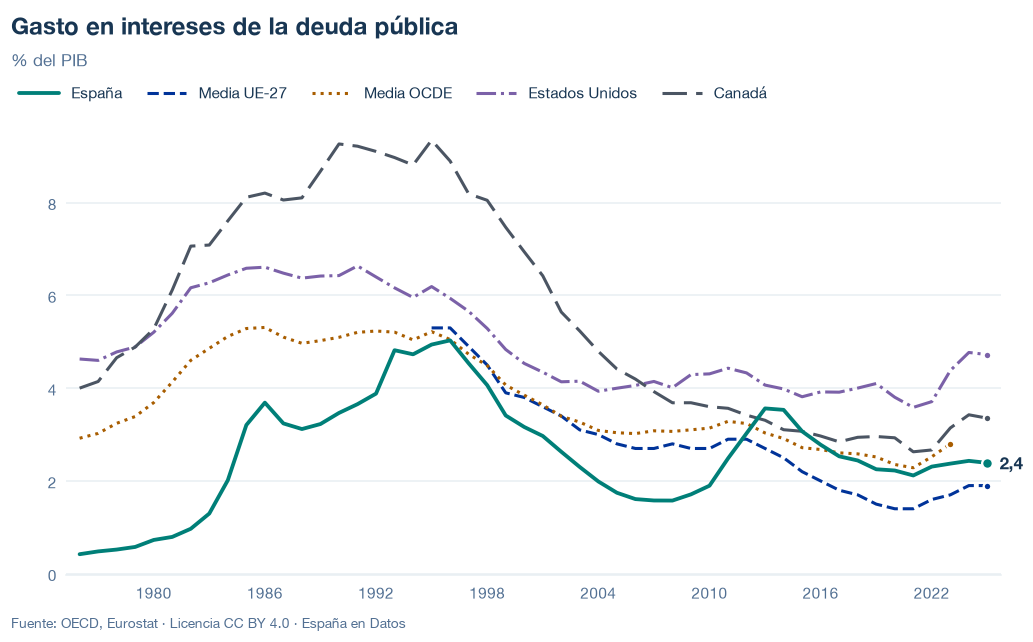

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/intereses-deuda-publica.json y data/intereses-deuda-publica.csv


## 6. Fuentes, notas y licencia

- OCDE, *Economic Outlook* (`OECD.ECO.MAD,DSD_EO@DF_EO`): `GGINTP` y `GDP` de España, EE. UU. y Canadá y, con `PPP`, de los países miembros para la media de la OCDE; para las comprobaciones, `GNINTQ` de los países miembros y del área `OECD`. Fichero *Last historical points* y documentación de la base de datos de la misma edición, enlazados en los metadatos del dataflow.
- OCDE, cuentas nacionales anuales (`OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12`): `D41` de EE. UU. y Canadá (comprobaciones).
- Eurostat, `gov_10a_main` (`D41PAY`: UE-27 y, para comparar, España) y `gov_10dd_edpt1` (PIB de España en millones de euros, comprobaciones).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.